| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_5_Diferenciacion_numerica.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_2_Heun.ipynb) |

# 7.1 Método de Euler: una recta por cada paso

Euler es el punto de partida para entender integración temporal. Derivaremos su actualización desde Taylor, mediremos orden uno y observaremos cómo un paso grande puede transformar un decaimiento físico en oscilación o explosión. También examinaremos un sistema oscilatorio y un ejemplo de estimación de parámetros.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Derivación desde Taylor

La expansión exacta es $y(t+h)=y(t)+hy'(t)+O(h^2)$. Sustituimos $y'=f(t,y)$ y descartamos el término restante:
$$\boxed{y_{n+1}=y_n+h f(t_n,y_n)}.$$
Geométricamente seguimos la tangente al inicio del intervalo. Para $y'=-ky$, $y_{n+1}=(1-kh)y_n$. Con $k=1$, $y_0=1$ y $h=0.2$, el primer paso vale $0.8$, mientras que el exacto vale $e^{-0.2}\approx0.81873$.

El error de un paso iniciado desde la solución exacta es $O(h^2)$; tras $O(1/h)$ pasos, y bajo estabilidad apropiada, el error global es $O(h)$. Algunos textos definen el error local dividido entre $h$ y lo llaman $O(h)$: revisa siempre la convención.

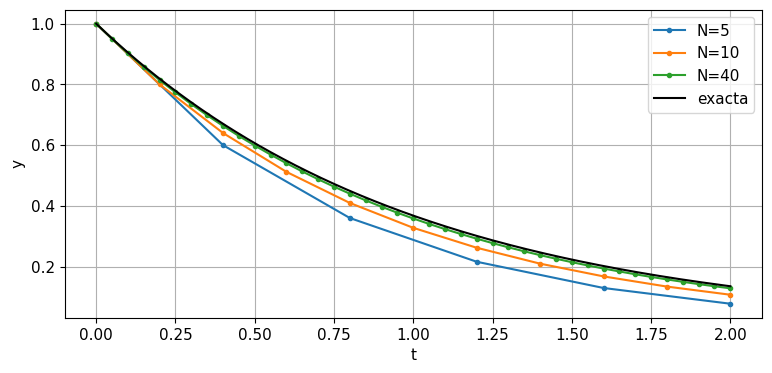

In [2]:
def euler(fun, tspan, y0, n):
    t = np.linspace(*tspan, n+1); h = t[1]-t[0]
    initial = np.atleast_1d(np.array(y0,dtype=float))
    y = np.empty((n+1,initial.size)); y[0] = initial
    for j in range(n):
        y[j+1] = y[j]+h*np.asarray(fun(t[j],y[j]))
    return t,y

for n in [5,10,40]:
    t,y = euler(lambda t,y:-y,(0,2),1.,n)
    plt.plot(t,y[:,0],"o-",markersize=3,label=f"N={n}")
q=np.linspace(0,2,500); plt.plot(q,np.exp(-q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Euler queda por debajo del decaimiento exacto con estos pasos positivos. Esa dirección del sesgo puede derivarse al comparar $1-h$ con $e^{-h}$. El refinamiento acerca las trayectorias, pero aumenta el número de evaluaciones linealmente.

## 3. Verificar el orden global

Para el problema de prueba, la solución numérica es $y_N=(1-T/N)^N$. Podemos medir el error final sin interpolar. Al duplicar $N$, un método de primer orden reduce el error aproximadamente por dos. La constante depende del intervalo y de la solución: decir orden uno no especifica un porcentaje de error universal.

Órdenes: [1.011832 1.005969 1.002996 1.0015  ]


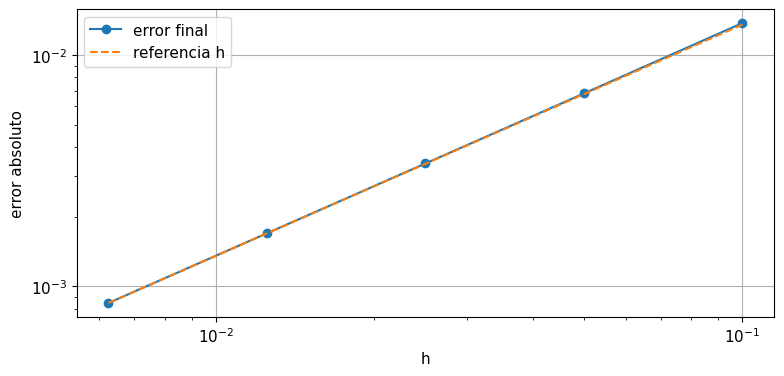

In [3]:
ns=np.array([20,40,80,160,320]); errors=[]
for n in ns:
    t,y=euler(lambda t,y:-y,(0,2),1.,n)
    errors.append(abs(y[-1,0]-np.exp(-2)))
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(2/ns,errors,"o-",label="error final")
plt.loglog(2/ns,errors[-1]*ns[-1]/ns,"--",label="referencia h")
plt.xlabel("h"); plt.ylabel("error absoluto"); plt.legend(); plt.show()

**Interpretación.** Las pendientes deben aproximarse a uno. Este estudio utiliza un problema suave y estable; repetirlo con un paso inestable no demuestra la tasa del método porque fallan las condiciones para converger.

## 4. Estabilidad y positividad

En $y'=\lambda y$, Euler amplifica cada paso por $R(z)=1+z$, $z=h\lambda$. La estabilidad absoluta exige $|1+h\lambda|\le1$. Para $\lambda=-k<0$ esto significa $0\le kh\le2$; para decaimiento estricto se necesita $0<kh<2$.

La positividad es más restrictiva: para $y_n\ge0$, se preserva con $kh\le1$. Así, un método puede ser estable y producir valores negativos oscilatorios. Concentración y población requieren atender esta propiedad además de la estabilidad.

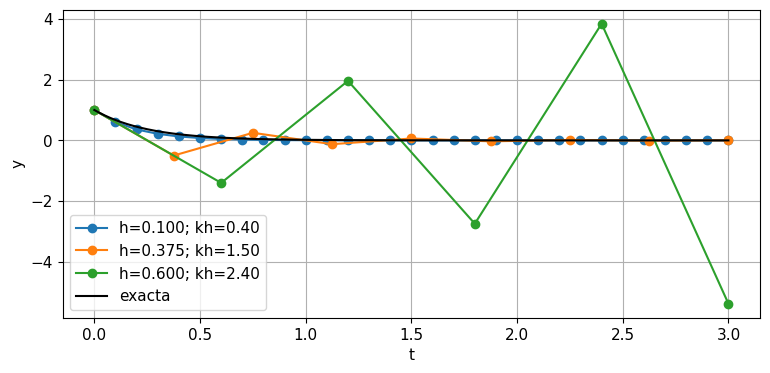

In [4]:
k=4.; T=3.
for n in [30,8,5]:
    t,y=euler(lambda t,y:-k*y,(0,T),1.,n)
    plt.plot(t,y[:,0],"o-",label=f"h={T/n:.3f}; kh={k*T/n:.2f}")
plt.plot(np.linspace(0,T,500),np.exp(-k*np.linspace(0,T,500)),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Con $kh=0.4$ la solución permanece positiva. Con $kh=1.5$ oscila con amplitud decreciente, y con $kh=2.4$ aumenta. La curva exacta decrece siempre: las oscilaciones se originan en la discretización.

## 5. Euler para un sistema

Para un oscilador $q'=p$, $p'=-q$, el estado es $y=(q,p)$. Euler actualiza simultáneamente ambos componentes usando el estado anterior:
$$q_{n+1}=q_n+hp_n,\qquad p_{n+1}=p_n-hq_n.$$
Si se modifica $q$ antes de calcular $p$, se obtiene otro método. Esta diferencia de implementación afecta energía y estabilidad. La energía exacta $E=(q^2+p^2)/2$ se conserva, pero Euler la multiplica por $1+h^2$ en cada paso.

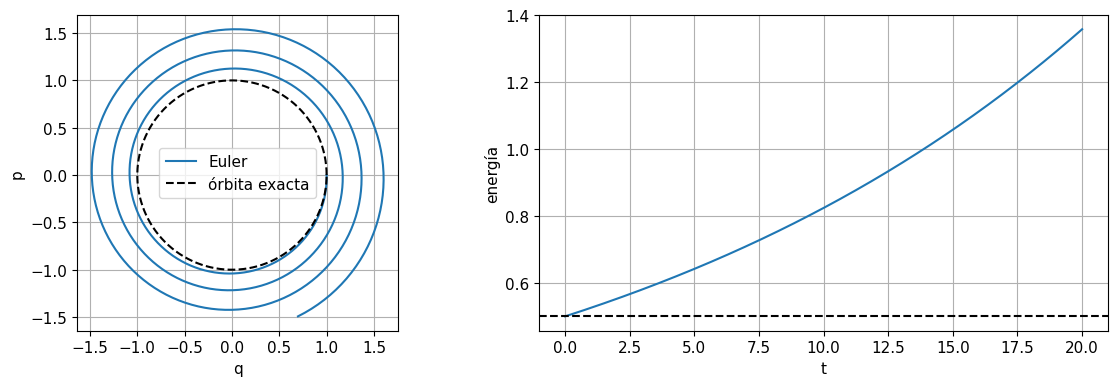

In [5]:
t,y=euler(lambda t,y:np.array([y[1],-y[0]]),(0,20),[1.,0.],400)
energy=0.5*np.sum(y*y,axis=1)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(y[:,0],y[:,1],label="Euler")
theta=np.linspace(0,2*np.pi,500); ax[0].plot(np.cos(theta),np.sin(theta),"k--",label="órbita exacta")
ax[0].set(xlabel="q",ylabel="p",aspect="equal"); ax[0].legend()
ax[1].plot(t,energy); ax[1].axhline(0.5,color="k",linestyle="--")
ax[1].set(xlabel="t",ylabel="energía"); plt.tight_layout(); plt.show()

**Interpretación.** La espiral creciente y la energía creciente son el mismo defecto visto en dos representaciones. Disminuir el paso reduce la deriva en un intervalo fijo, pero Euler explícito no tiene una región estable que contenga el eje imaginario salvo el origen.

## 6. Tiempo dependiente y escala de la pendiente

Cuando $f$ depende explícitamente de $t$, evalúalo en el tiempo del comienzo del paso. Para $y'=t$, $y(0)=0$, Euler produce una suma de rectángulos izquierdos y $y(T)$ aproxima $T^2/2$. Es una conexión directa entre cuadratura e integración de ODE.

Si se cambia segundos por milisegundos, también debe cambiar la definición de $f$ o de su parámetro $k$. Un paso numérico no tiene significado sin unidad. Antes de elegir $h$, identifica la escala temporal más rápida que deseas resolver.

In [6]:
for n in [5,10,20]:
    t,y=euler(lambda t,y:np.full_like(y,t),(0,1),0.,n)
    print(f"N={n}, y(1)={y[-1,0]:.6f}, error={y[-1,0]-0.5:.6f}")

N=5, y(1)=0.400000, error=-0.100000
N=10, y(1)=0.450000, error=-0.050000
N=20, y(1)=0.475000, error=-0.025000


**Interpretación.** La suma izquierda subestima la integral de una función creciente. El error final es $-h/2$ en este caso, una verificación exacta del orden uno.

## 7. Estimar un parámetro con un simulador aproximado

Generamos un dato exacto $y(1)=e^{-k_*}$ con $k_*=1$. Ajustamos $k$ usando el valor final de Euler. Una malla gruesa puede reproducir el dato con un parámetro distinto de $k_*$. Este es un ejemplo mínimo de sesgo numérico en un problema inverso.

No agregamos ruido para aislar la discretización. Si hubiese ruido, la discrepancia total incluiría ambas fuentes y sería más difícil atribuirla.

In [7]:
observed=np.exp(-1.)
for n in [5,10,40,160]:
    def objective(k):
        _,y=euler(lambda t,y:-k*y,(0,1),1.,n)
        return (y[-1,0]-observed)**2
    fit=minimize_scalar(objective,bounds=(0.2,2.),method="bounded")
    print(f"N={n:3d}, k estimado={fit.x:.8f}, verdadero=1")

N=  5, k estimado=0.90634500, verdadero=1
N= 10, k estimado=0.95162598, verdadero=1
N= 40, k estimado=0.98760409, verdadero=1
N=160, k estimado=0.99688217, verdadero=1


**Interpretación.** El parámetro estimado se acerca al verdadero al refinar. Un error de ajuste diminuto puede coexistir con un parámetro incorrecto: el optimizador compensó el sesgo del simulador.

## 8. Cuándo usar Euler

Es útil para derivaciones, prototipos, comprobar estructuras de datos y problemas donde un paso muy pequeño ya sea obligatorio por otras restricciones. Una única evaluación de $f$ por paso facilita entender el coste. Para gran precisión en problemas suaves, métodos de orden superior suelen ser más eficientes.

En métodos para PDE, Euler temporal combinado con diferencias espaciales puede imponer un paso $\Delta t=O(\Delta x^2)$ para difusión. Refinar el espacio exige refinar el tiempo por estabilidad, aunque la forma espacial parezca correcta. Esta es una de las razones para estudiar métodos implícitos.

## 9. Comprobaciones de implementación

Comprueba $y'=0$: todos los estados deben permanecer iguales al inicial. Comprueba $y'=c$: Euler debe reproducir exactamente la recta, salvo redondeo. Verifica el número de puntos $N+1$ y la forma del arreglo para estados vectoriales. Escribe la actualización en una nueva fila para evitar usar componentes ya modificados.

Si el resultado da valores infinitos o amplitudes crecientes inesperadas, evalúa $h\lambda$ antes de atribuirlo al modelo. Para sistemas no lineales, el jacobiano local ofrece una orientación de escalas, aunque una prueba lineal no establece una garantía global.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

Si un método tiene orden global $p=1$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método de Euler genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_5_Diferenciacion_numerica.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_2_Heun.ipynb) |